# Setup

In [7]:
import json
import random
from math import inf
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.utils as utils
from torchvision.datasets import CelebA
from tqdm import tqdm
from transformers import CLIPModel, CLIPProcessor

random.seed(7)

In [8]:
# constants
CLIP_VERSION = "openai/clip-vit-base-patch32"
DATA_DIR = Path("../data")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SRC_DIR = DATA_DIR.parent / "src"
# adjust for Google Colab
Path.exists(DATA_DIR)

True

# LoRA

- **Intuition:** Retraining a model means updating *all* its weights W to learn a new task. What if we could train a much smaller set of weights and achieve the same effect?

- **Low-Rank Adaptation (LoRA)** makes this possible:
    1. Freeze the pretrained weight matrix W (shape m×n)
    2. Introduce two low-rank matrices: B (shape=m×r) and A (shape=r×n), with rank r ≪ min(m, n)
    3. The weight update we want to compute is ΔW. We can approximate it as ΔW = BA, which is low-rank. ΔW shape remains m×n, but the number of parameters is now r(m+n) instead of mn.
    4. During training, we only update B and A, while W remains frozen.
    5. At inference time, we compute the effective weight as W + ΔW. This allows us to adapt the model to new tasks with far fewer parameters.

- **Why it works:** The hypothesis is that task-specific weight updates live in a low-rank subspace. LoRA captures that subspace with far fewer parameters.

Credit to [Umar](https://www.youtube.com/watch?v=PXWYUTMt-AU) for visual explanation.

In [163]:
model = CLIPModel.from_pretrained(CLIP_VERSION)
model

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 6170.51it/s]


CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1e-05, eleme


-  We inject low-rank adapters into the Q, K, and V projection layers of CLIP's text encoder we can see in the cell output above Each one gets its own B and A matrices. The vision encoder, text projection layer, etc... stay frozen.

- **Why only the text encoder?** Our goal is to learn better text representations for attribute queries ("Smiling", "Eyeglasses", etc.). The visual understanding of faces is already good enough — we don't need to change how CLIP sees images, only how it represents the text descriptions of attributes.

- **Why Q, K, V specifically?** These are the matrices that control how attention operates — what each token attends to and how it transforms its representation. Tweaking them lets LoRA reshape how CLIP processes an attribute word like "Smiling" without changing the broader language understanding stored in the feed-forward layers and embedding table.


In [164]:
class LoRA(nn.Module):
    def __init__(self, in_features, out_features, rank=1, alpha=1):
        super().__init__()

        # Section 4.1 of the paper:
        #   We use a random Gaussian initialization for A and zero for B,
        #   so ∆W = BA is zero at the beginning of training
        self.lora_B = nn.Parameter(torch.zeros((out_features, rank), device=DEVICE))
        self.lora_A = nn.Parameter(torch.zeros((rank, in_features), device=DEVICE))
        nn.init.normal_(self.lora_A, mean=0, std=1)

        # Section 4.1 of the paper:
        #   We then scale ∆Wx lora_y α/r , where α is a constant in r.
        #   When optimizing with Adam, tuning α is roughly the same as tuning the learning rate if we scale the initialization appropriately.
        #   As a result, we simply set α to the first r we try and do not tune it.
        #   This scaling helps to reduce the need to retune hyperparameters when we vary r.
        self.scale = alpha / rank
        self.enabled = True

    def forward(self, W):
        return W + ((self.lora_B @ self.lora_A) * self.scale)

In [165]:
def AddLoRA(layer, rank=1, alpha=1):
    # Only add the parameterization to the weight matrix, ignore the Bias

    # From section 4.2 of the paper:
    #   We limit our study to only adapting the attention weights for downstream tasks and freeze the MLP modules (so they are not trained in downstream tasks) both for simplicity and parameter-efficiency.

    features_out, features_in = layer.weight.shape
    return LoRA(features_in, features_out, rank=rank, alpha=alpha)

In [166]:
def adapt(model, rank=4):
    for layer in model.text_model.encoder.layers:
        for attn_layer in [layer.self_attn.q_proj, layer.self_attn.k_proj, layer.self_attn.v_proj]:
            utils.parametrize.register_parametrization(attn_layer, "weight", AddLoRA(attn_layer, rank))

helper function to setup a fresh CLIP model for each training run

In [167]:
def reset_model():
    model = CLIPModel.from_pretrained(CLIP_VERSION)
    model = model.to(DEVICE)
    adapt(model)

    for name, param in model.named_parameters():
        param.requires_grad = False

    for name, param in model.named_parameters():
        if "lora" in name:
            param.requires_grad = True

    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%)")

    return model

# Training Data

In [168]:
celeba_test = CelebA(root=DATA_DIR, split="test", download=False)
celeba_train = CelebA(root=DATA_DIR, split="train", download=False)
len(celeba_test), len(celeba_train)

(19962, 162770)

- We follow a similar reasoning to how the `eval.json` file was developed, but with the following adaptations:

```json
{
    "Smiling": [
        (ref_idx, [pos1, pos2, ..., pos10], [neg1, neg2, ..., neg50]),
        (ref_idx, [pos1, ...], [neg1, ...]),
        ...
    ],
    "Eyeglasses": [
        ...
    ],
    ... 
}
```


- For a given attribute (e.g. "Smiling"), split images into *has it* vs *doesn't have it*
    - Positives = images with the attribute + similar on the other 39 attributes (hamming distance ≤ 2)
    - Negatives = images without the attribute + similar on the other 39 attributes (hamming distance ≤ 5)
    - This makes the queried attribute the *main* difference between positive and negative pairs

- We train on single-attribute queries only (e.g. "+Smiling"). Multi-attribute and negative-only queries are handled later by geometric composition in Threads 2 and 4. LoRA's job is to produce better single-attribute embeddings to feed into that pipeline.


In [169]:
attribute2idx = {name: idx for idx, name in enumerate(celeba_train.attr_names[:40])}

In [ ]:
def build_training_examples(celeba_data, max_refs=50, pos_hd_max=2, neg_hd_max=5):
    results = {}

    for attr_name, attr_idx in tqdm(list(attribute2idx.items()), desc="Attributes"):
        results[attr_name] = []

        # Mask for the other 39 attributes (exclude the queried one)
        other_mask = torch.ones(40, dtype=torch.bool)
        other_mask[attr_idx] = False

        # Refs: images that have the queried attribute
        has_attr = celeba_data.attr[:, attr_idx] == 1
        lacks_attr = ~has_attr
        ref_indices = has_attr.nonzero(as_tuple=True)[0]

        for ref_idx in ref_indices[:max_refs]:
            ref_other = celeba_data.attr[ref_idx][other_mask]

            # hamming distance on the other 39 attributes
            other_attrs = celeba_data.attr[:, other_mask]
            hd_other = (other_attrs != ref_other).sum(dim=1)

            # Positives: have the attribute + hamming distance ≤ pos_hd_max on other 39
            pos_mask = has_attr & (hd_other <= pos_hd_max)
            pos_mask[ref_idx] = False
            positives = pos_mask.nonzero(as_tuple=True)[0]

            # Negatives: LACK the attribute + low HD on other 39 (hard negatives)
            neg_mask = lacks_attr & (hd_other <= neg_hd_max)
            negatives = neg_mask.nonzero(as_tuple=True)[0]

            if len(positives) >= 1 and len(negatives) >= 1:
                results[attr_name].append((ref_idx, positives[:10], negatives[:50]))

    return results

In [171]:
def train_val_split(examples):
    train_examples = {}
    val_examples = {}

    for attr_name, data in examples.items():
        random.shuffle(data)
        split = int(0.8 * len(data))
        train_examples[attr_name] = data[:split]
        val_examples[attr_name] = data[split:]

    return train_examples, val_examples

In [172]:
def visualize_examples(attr_name, ref_idx, pos_indices, neg_indices, n_show=5):
    """Visualize a reference image with its positives and negatives."""
    fig, axes = plt.subplots(1, 1 + min(n_show, len(pos_indices)) + min(n_show, len(neg_indices)), figsize=(15, 3))

    # Reference
    img_ref, attrs_ref = celeba_train[ref_idx]
    axes[0].imshow(img_ref)
    axes[0].set_title(f"Ref\n{attr_name}")
    axes[0].axis("off")

    # Positives
    for i, idx in enumerate(pos_indices[:n_show]):
        img, attrs = celeba_train[idx]
        axes[1 + i].imshow(img)
        hd = (attrs != attrs_ref).sum().item()
        axes[1 + i].set_title(f"+ve (HD={hd})")
        axes[1 + i].axis("off")

    # Negatives
    offset = 1 + min(n_show, len(pos_indices))
    for i, idx in enumerate(neg_indices[:n_show]):
        img, attrs = celeba_train[idx]
        axes[offset + i].imshow(img)
        hd = (attrs != attrs_ref).sum().item()
        axes[offset + i].set_title(f"-ve (HD={hd})")
        axes[offset + i].axis("off")

    plt.tight_layout()
    plt.show()

- We build 2 sets, one with 50 examples per attribute, and the other with 100. 
- We comment out the build process and load the prebuilt examples for reporting purposes.

In [173]:
# examples = build_training_examples(celeba_train)

In [174]:
# train_examples_50, val_examples_50 = train_val_split(examples)
# torch.save(train_examples_50, f"{SRC_DIR}/train_examples_50.pt")
# torch.save(val_examples_50, f"{SRC_DIR}/val_examples_50.pt")

In [175]:
# small subset split
train_examples_50 = torch.load(f"{SRC_DIR}/train_examples_50.pt")
val_examples_50 = torch.load(f"{SRC_DIR}/val_examples_50.pt")

In [176]:
train_examples_50["Smiling"][0]

(tensor(62),
 tensor([ 381,  631,  736,  892,  939, 1001, 1009, 1022, 1068, 1788]),
 tensor([   5,    9,   33,   34,   57,   84,   87,   97,  100,  140,  161,  189,
          197,  206,  250,  256,  257,  289,  322,  325,  396,  431,  444,  462,
          468,  543,  548,  549,  597,  608,  655,  678,  714,  733,  737,  740,
          768,  792,  865,  869,  944,  997, 1004, 1017, 1041, 1067, 1069, 1070,
         1079, 1083]))

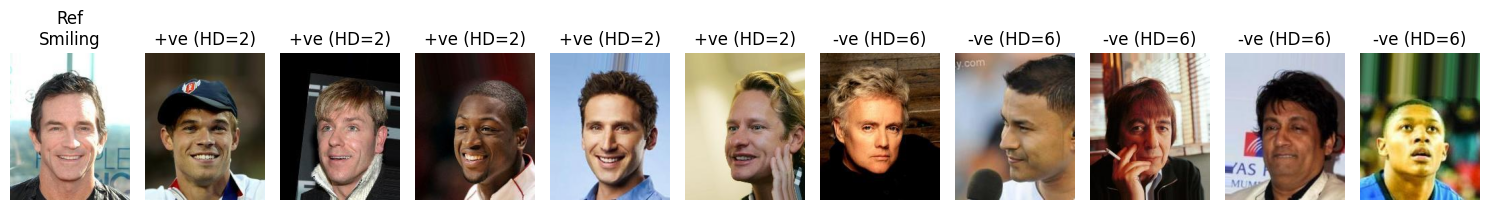

In [177]:
ref, pos, neg = train_examples_50["Smiling"][10]
visualize_examples("Smiling", ref, pos, neg)

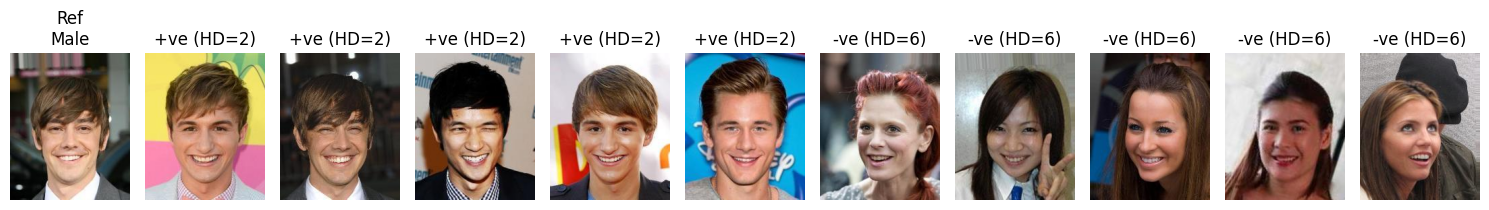

In [178]:
ref, pos, neg = train_examples_50["Male"][10]
visualize_examples("Male", ref, pos, neg)

## Embedding training images

- We embed all train split images similar to how we embed the test split for evaluation.

In [179]:
processor = CLIPProcessor.from_pretrained(CLIP_VERSION)

model = CLIPModel.from_pretrained(CLIP_VERSION)
model = model.to(DEVICE)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 7737.74it/s]


In [180]:
def embed(model, inputs, type="img"):
    with torch.inference_mode():
        if type == "img":
            embeddings = model.get_image_features(inputs)
        if type == "text":
            embeddings = model.get_text_features(inputs)

        embeddings = F.normalize(embeddings.pooler_output, p=2, dim=-1)
        return embeddings


def embed_images(model, dataset, batch_size=128):
    """embeds all images in celeba dataset(train/test) and returns the resulting tensor."""

    num_imgs = len(dataset)
    batches = []

    for cutoff in range(0, num_imgs, batch_size):
        imgs = [dataset[idx][0] for idx in range(cutoff, min(cutoff + batch_size, num_imgs))]
        inputs = processor(images=imgs, return_tensors="pt")
        inputs = inputs["pixel_values"].to(DEVICE)

        embeddings = embed(model, inputs)
        batches.append(embeddings)

    db = torch.cat(batches, dim=0)
    return db

In [181]:
# train_img_embed_db = embed_images(model, celeba_train)
# train_img_embed_db.shape

In [182]:
# torch.save(train_img_embed_db, f"{SRC_DIR}/train_img_embed_db.pt")

In [183]:
train_img_embed_db = torch.load(f"{SRC_DIR}/train_img_embed_db.pt")
train_img_embed_db.shape

torch.Size([162770, 512])

# Training Setup

The LoRA paper used:

- **Rank:** r = 4 or r = 8 as defaults on GPT-3. We use r = 4 to keep the number of trainable parameters low and avoid overfitting on our small dataset.

- **Learning rate:** 1e-4 for GPT-3 experiments (Adam), and 4e-4 for RoBERTa. We use 1e-4

## Loss



- Given a query like "+Smiling" paired with a reference image, the model needs to pick the matching image from a set of candidates: 1 face that shares the attribute, and 10 that don't but look otherwise similar.

- InfoNCE loss frames this as a classification problem: among all 11 candidates, which one is the right match? The loss pushes the model to assign a high score to the correct pair and low scores to every other pair. Mathematically, it softmaxes the cosine similarities between query and candidates, then uses cross-entropy with the correct answer always at position 0.

- We also add a regularization term to the loss that penalizes how far the LoRA-modified attribute embeddings drift from the original CLIP embeddings. This way LoRA can adjust embeddings where needed, but pays a cost for drifting too far — protecting attributes where CLIP already works well.

In [184]:
def infonce_loss(query, pos_img, neg_imgs, pos_attr, pos_attr_lora, img_embed_db, attr_embed_db, temperature=0.07, l2_reg=1):
    """
    total loss = info_nce + regularizing_term * squared_l2(attr_lora, attr_frozen)
    """

    pos_img_frozen = img_embed_db[pos_img].unsqueeze(0)
    neg_imgs_frozen = img_embed_db[neg_imgs]
    imgs_frozen = torch.cat((pos_img_frozen, neg_imgs_frozen), dim=0)

    logits = (query @ imgs_frozen.T) / temperature
    loss = F.cross_entropy(logits, torch.zeros(1, dtype=torch.long, device=logits.device))

    pos_attr_frozen = attr_embed_db[attribute2idx[pos_attr]]

    penalty = l2_reg * F.mse_loss(pos_attr_lora.squeeze(0), pos_attr_frozen)

    return loss + penalty

## Utilities

In [185]:
processor = CLIPProcessor.from_pretrained(CLIP_VERSION)


def embed_single_attribute(model, attr):
    text = attr.replace("_", " ")
    text = processor(text=text, return_tensors="pt", padding=True)
    text = text["input_ids"].to(DEVICE)
    attr_embed = model.get_text_features(text)
    attr_embed = F.normalize(attr_embed.pooler_output, p=2, dim=-1)
    return attr_embed

In [186]:
def train(model, optimizer, l2_reg, train_examples, img_embed_db, attr_embed_db, epoch=1):
    model.train()

    train_examples_flat = [(attr, ref, pos, neg) for attr, pairs in train_examples.items() for ref, pos, neg in pairs]

    total = 0

    data_iterator = tqdm(train_examples_flat, desc=f"[train] epoch-{epoch + 1}", ncols=0, bar_format="{n_fmt}/{total_fmt} [{elapsed}<{remaining}]")

    for attr, ref, pos, neg in data_iterator:
        optimizer.zero_grad()

        ref_embed = img_embed_db[ref].unsqueeze(0)
        attr_lora = embed_single_attribute(model, attr)
        query = ref_embed + attr_lora
        query = F.normalize(query, p=2, dim=-1)

        loss = infonce_loss(query, pos[0], neg[:10], attr, attr_lora, img_embed_db, attr_embed_db, l2_reg=l2_reg)
        loss.backward()

        total += loss.item()

        # DEBUG GRADIENTS
        lora_grad_norm = sum(p.grad.norm() for p in model.parameters() if p.requires_grad and p.grad is not None)

        data_iterator.set_postfix(loss=total / (data_iterator.n + 1), grad=lora_grad_norm.item())

        optimizer.step()

    return total / len(train_examples_flat)

In [187]:
def validate(model, l2_reg, val_examples, img_embed_db, attr_embed_db, epoch):
    total = 0

    with torch.inference_mode():
        val_examples_flat = [(attr, ref, pos, neg) for attr, pairs in val_examples.items() for ref, pos, neg in pairs]

        data_iterator = tqdm(val_examples_flat, desc=f"[val] epoch-{epoch + 1}", ncols=0, bar_format="{n_fmt}/{total_fmt} [{elapsed}<{remaining}]")

        for attr, ref, pos, neg in data_iterator:
            ref_embed = img_embed_db[ref].unsqueeze(0)
            attr_lora = embed_single_attribute(model, attr)
            query = ref_embed + attr_lora
            query = F.normalize(query, p=2, dim=-1)

            loss = infonce_loss(query, pos[0], neg[:10], attr, attr_lora, img_embed_db, attr_embed_db, l2_reg=l2_reg)
            total += loss.item()

            data_iterator.set_postfix(loss=total / (data_iterator.n + 1))

        return total / len(val_examples_flat)

In [ ]:
def learn(train_examples, val_examples, img_embed_db, attr_embed_db, l2_reg, epochs=10, checkpoint_name="model_checkpoint"):
    model = reset_model()

    trainable = filter(lambda p: p.requires_grad, model.parameters())
    optimizer = torch.optim.Adam(trainable, lr=1e-4)

    best_val_loss = float("inf")
    patience = 3

    for epoch in range(epochs):
        train_loss = train(model, optimizer, l2_reg, train_examples, img_embed_db, attr_embed_db, epoch)
        val_loss = validate(model, l2_reg, val_examples, img_embed_db, attr_embed_db, epoch)

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            # Save only the LoRA parameters
            lora_state = {k: v for k, v in model.state_dict().items() if "lora" in k}
            torch.save(lora_state, f"{SRC_DIR}/{checkpoint_name}.pt")

            patience = 3
        else:
            patience -= 1

        print(f"epoch-{epoch + 1} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | best={best_val_loss:.4f}")

        if patience <= 0:
            break

# Training Runs

- We trained 2 versions of the model, one on 50 examples per attribute and the other on 100. We capped the runs to 10 epochs each to keep the training time reasonable. Checkpoints were saved as `model_checkpoint_50.pt` and `model_checkpoint_100.pt` respectively.
- Afterwards we evaluated both models on the retrieval task and compared their performance to the baseline.

In [189]:
attr_embed_db = torch.load(f"{SRC_DIR}/attr_embed_db.pt")
train_img_embed_db = torch.load(f"{SRC_DIR}/train_img_embed_db.pt")
celeba_train = CelebA(root=DATA_DIR, split="train", download=False)
attribute2idx = {name: idx for idx, name in enumerate(celeba_train.attr_names[:40])}

In [190]:
train_examples_50 = torch.load(f"{SRC_DIR}/train_examples_50.pt")
val_examples_50 = torch.load(f"{SRC_DIR}/val_examples_50.pt")

In [191]:
# learn(train_examples_50, val_examples_50, train_img_embed_db, attr_embed_db, l2_reg=1, epochs=10, checkpoint_name="model_checkpoint_50")

In [192]:
train_examples_100 = torch.load(f"{SRC_DIR}/train_examples_100.pt")
val_examples_100 = torch.load(f"{SRC_DIR}/val_examples_100.pt")

In [193]:
# learn(train_examples_100, val_examples_100, train_img_embed_db, attr_embed_db, l2_reg=1, epochs=10, checkpoint_name="model_checkpoint_100")

# Evaluation

## Utilities

In [194]:
annotations_path = Path(f"{DATA_DIR}/celeba_evaluation.json")
annotations_path.exists()

True

In [195]:
with open(annotations_path, "r") as f:
    annotations = json.load(f)
len(annotations)

14

In [196]:
def sum_up(attributes, *, text_db=None, model=None):
    if not attributes:
        return torch.zeros(1, 512).to(DEVICE)

    embeds = []
    for attr in attributes:
        if text_db is not None:
            embeds.append(text_db[attribute2idx[attr]].unsqueeze(0))
        elif model is not None:
            embeds.append(embed_single_attribute(model, attr))
        else:
            raise ValueError("Pass either text_db or model")

    return torch.sum(torch.cat(embeds, 0), 0, keepdim=True)


def compute_similarity(query, db, ref_idx, k=10):
    # (19k,512)*(512,1)
    score = db @ query.T

    # modify the score of ref_img to eliminate it from top-k
    score[ref_idx] = -inf
    sorted_scores, img_idxs = torch.sort(score, dim=0, descending=True)
    top_k = (torch.flatten(img_idxs[:k])).tolist()

    return top_k

In [197]:
def evaluate_retrieval(retrieved_indices: list[int], ground_truth_indices: list[int], k: int, log: bool = True) -> dict:
    """
    Evaluate the retrieval performance for a single source image.

    Args:
    ----
        retrieved_indices: list of image IDs predicted by the model,
            ordered by similarity (descending).
        ground_truth_indices: list of valid target IDs from the benchmark JSON.
        k: the cutoff for top-K evaluation (e.g., 1, 5, 10).

    Return:
    ------
        A dictionary containing Recall@K and Precision@K.

    """
    if log:
        print(f"retrieved={retrieved_indices[:k]}")
        print(f"truth={ground_truth_indices[:k]}")

    # Isolate the top K predictions
    top_k_retrieved = retrieved_indices[:k]

    # Calculate the intersection between predictions and ground truth
    hits = set(top_k_retrieved).intersection(set(ground_truth_indices))
    num_hits = len(hits)

    # Metrics calculations
    # Recall@K (Hit Rate): 1 if at least one match is found, 0 otherwise
    recall_at_k = 1 if num_hits > 0 else 0

    # Precision@K: Fraction of top K predictions that are correct
    precision_at_k = num_hits / k

    return {f"Recall@{k}": recall_at_k, f"Precision@{k}": precision_at_k}

In [198]:
def initialize_scores():
    scores = {}
    for annotation in annotations:
        attributes = annotation["query"]
        refs = annotation["ground_truth"].keys()
        scores[attributes] = {"ref_counts": len(refs)}

        for k in [1, 5, 10]:
            recall = f"Recall@{k}"
            precision = f"Precision@{k}"
            scores[attributes][recall] = 0
            scores[attributes][precision] = 0

    return scores

In [199]:
def log(result, query, k, scores):
    # result example: {"Recall@1": 0, "Precision@2": 0}
    recall = f"Recall@{k}"
    precision = f"Precision@{k}"

    scores[query][recall] += result[recall]
    scores[query][precision] += result[precision]

In [ ]:
def retrieve(annotation, img_db, model, scores):
    # split annotation string into invididual attributes
    attributes = annotation["query"].split(",")
    attributes = [attr.strip() for attr in attributes]

    # isolate the +ve and -ve attributes
    positive_attributes = []
    negative_attributes = []
    for attribute in attributes:
        if attribute[0] == "+":
            positive_attributes.append(attribute[1:])
        elif attribute[0] == "-":
            negative_attributes.append(attribute[1:])

    # sum up each set
    positive_attributes = sum_up(positive_attributes, model=model)
    negative_attributes = sum_up(negative_attributes, model=model)

    # retrieve all the image reference for the query
    refs = [int(value) for value in list(annotation["ground_truth"].keys())]

    for idx in refs:
        # get embedding representation
        img_embed = img_db[idx]

        # apply naive addition and subtruction of the  attributes to the img embed
        # q = v_ref + Σ [+]attr - Σ [-]attr
        query = img_embed + positive_attributes - negative_attributes

        top_10 = compute_similarity(query, img_db, idx)

        # score perfomance
        ground_truths = annotation["ground_truth"][str(idx)]

        for k in [1, 5, 10]:
            # result struct: {"Recall@k": 0, "Precision@k": 0}
            result = evaluate_retrieval(top_10, ground_truths, k, log=False)
            log(result, annotation["query"], k, scores)

In [201]:
def compute_averages(scores):
    avg_scores = {}
    for query in scores.keys():
        avg_scores[query] = {}
        counts = scores[query]["ref_counts"]
        for k in [1, 5, 10]:
            avg_scores[query][f"Recall@{k}"] = round((scores[query][f"Recall@{k}"] / counts), 4)
            avg_scores[query][f"Precision@{k}"] = round((scores[query][f"Precision@{k}"] / counts), 4)

    return avg_scores

In [202]:
def retrieve_all(annotations, img_db, model):
    scores = initialize_scores()
    for annotation in annotations:
        retrieve(annotation, img_db, model, scores)

    averages = compute_averages(scores)
    return averages

In [203]:
def evaluate_models(versions):
    test_img_embeddings = torch.load(f"{SRC_DIR}/test_img_embed_db.pt")

    scores = {}

    for version in versions:
        model = reset_model()
        model.load_state_dict(torch.load(f"{SRC_DIR}/lora_checkpoint_{version}.pt"), strict=False)
        model.eval()

        model_scores = retrieve_all(annotations, test_img_embeddings, model)
        scores[f"model_{version}"] = model_scores

    return scores

In [204]:
def save_results(scores):
    with open(f"{SRC_DIR}/results.json", "r+") as file:
        file_data = json.load(file)

        for key, value in scores.items():
            file_data[key] = value
        file.seek(0)

        json.dump(file_data, file, indent=2)
        file.truncate()

In [205]:
def compare_results(results, metric="Recall@10"):
    models = list(results.keys())
    queries = list(next(iter(results.values())).keys())
    x = np.arange(len(queries))
    w = 0.25

    fig, ax = plt.subplots(figsize=(16, 5))
    for i, model in enumerate(models):
        vals = [results[model][q][metric] * 100 for q in queries]
        ax.bar(x + i * w, vals, w, label=model)

    ax.set_xticks(x + w)
    ax.set_xticklabels(queries, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel(f"{metric} (%)")
    ax.set_title(f"{metric}")
    ax.legend()
    plt.tight_layout()
    plt.show()

## Results

In [ ]:
# results = evaluate_models(["50", "100"])
# save_results(results)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 7761.56it/s]


Trainable: 147,456 / 151,424,769 (0.10%)


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 6343.73it/s]


Trainable: 147,456 / 151,424,769 (0.10%)


In [209]:
# load the results
with open(f"{SRC_DIR}/results.json", "r") as f:
    results = json.load(f)
len(results)

3

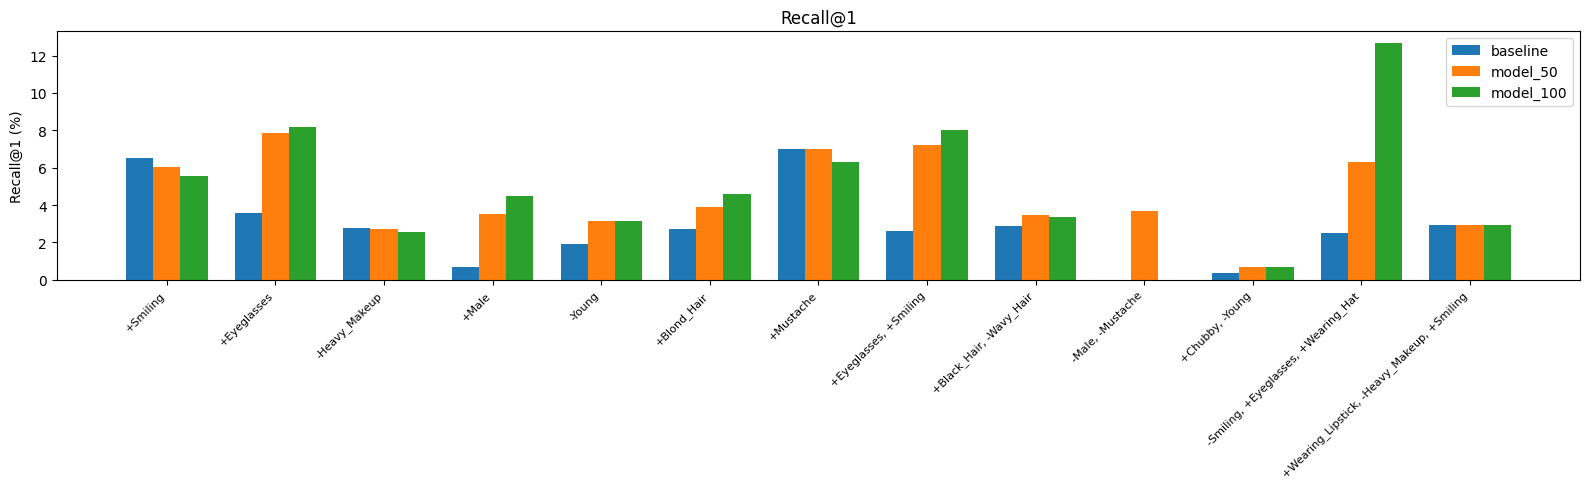

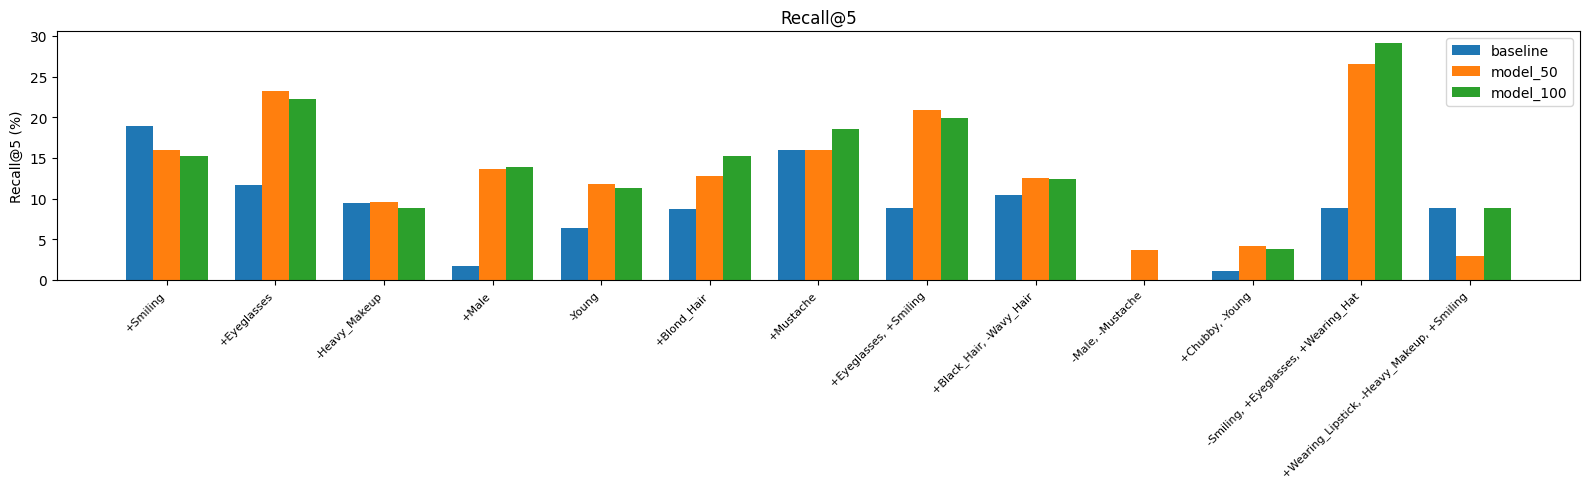

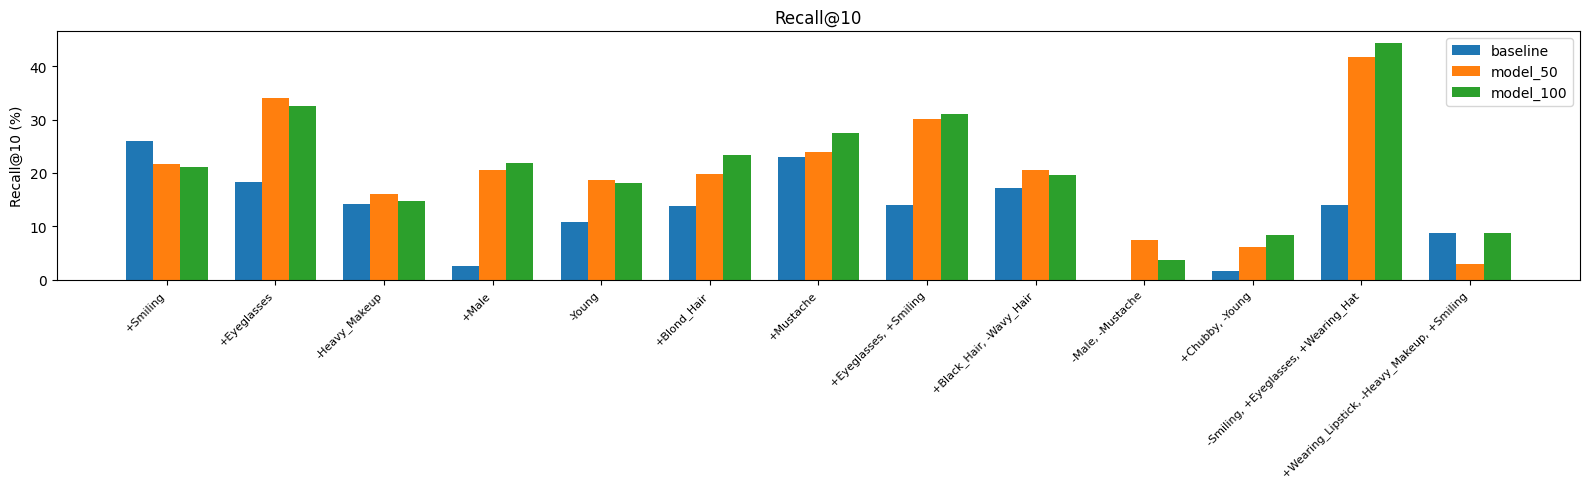

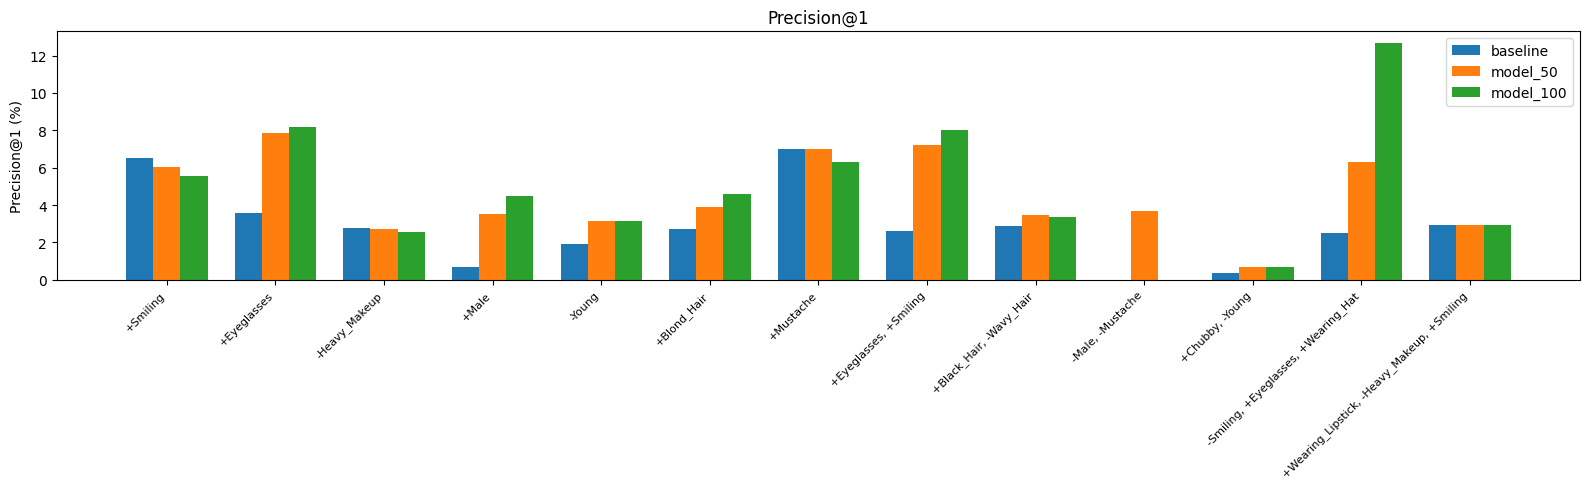

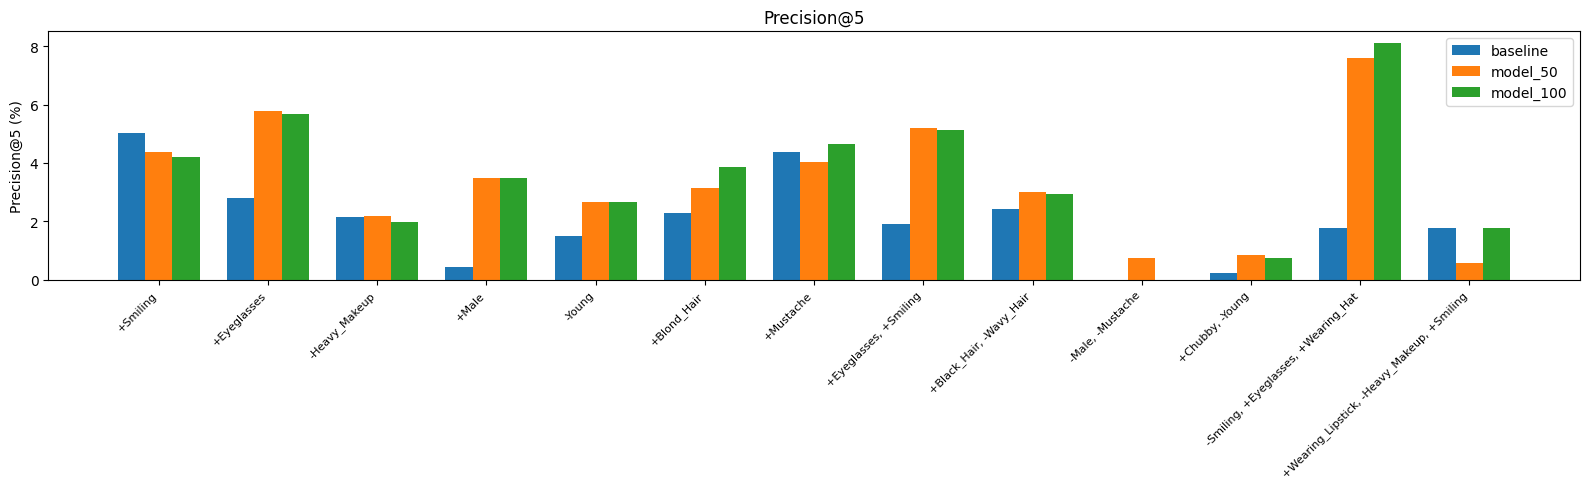

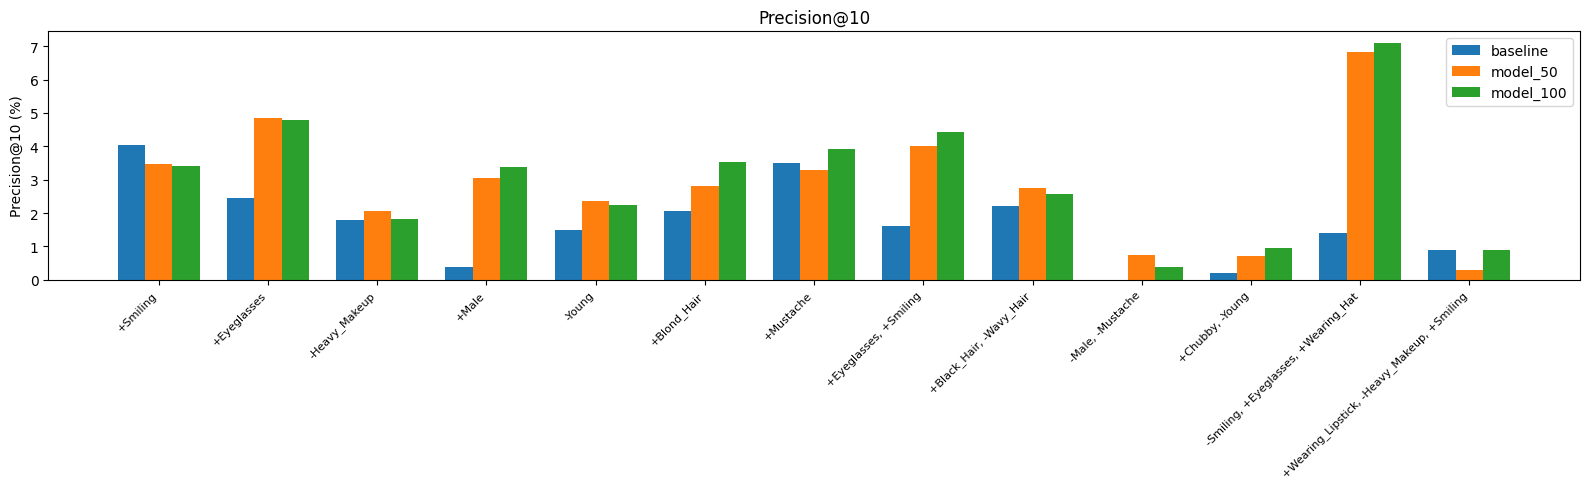

In [210]:
for metric in ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]:
    compare_results(results, metric)

# Conclusions

- **LoRA improves retrieval over the baseline, with the clearest gains on multi-attribute queries.** On single-attribute queries the gains are modest or occasionally negative (e.g. `+Smiling` drops from 26.03% to 21.04% at Recall@10).

- **Multi-attribute queries benefit the most.** The largest improvements appear on compound queries:
  - `-Smiling, +Eyeglasses, +Wearing_Hat`: Recall@10 jumps from 13.92% (baseline) to 44.30% (model_100)
  - `+Eyeglasses, +Smiling`: Recall@10 from 14.05% to 31.05%
  - `-Male, -Mustache`: baseline scores 0% across all K to model_50 reaches 7.41% at Recall@10

- **More data (100 vs 50 examples per attribute) does not have a consistent effect.** model_100 outperforms model_50 on several multi-attribute queries (e.g. `-Smiling, +Eyeglasses, +Wearing_Hat` at Recall@1: 12.66% vs 6.33%), but underperforms on others (e.g. `+Eyeglasses` at Recall@10: 32.56% vs 34.11%).

- `+Wearing_Lipstick, -Heavy_Makeup, +Smiling` stays flat or degrades across both LoRA models. This may be because the three attributes interact in a way that simple single attribute addition examples cannot capture

- Lets combine what we have with the geometric composition approach from Thread 2 and see if we can get better results on multi-attribute queries.


# Save data to Hugging Face Hub

In [12]:
from huggingface_hub import HfApi, hf_hub_download, login

In [ ]:
login()

In [11]:
def upload_files_to_hf(files, repo_id, src_dir):
    api = HfApi()
    api.create_repo(repo_id=repo_id, repo_type="dataset", exist_ok=True)

    for fname in files:
        api.upload_file(
            path_or_fileobj=str(f"{src_dir}/{fname}"),
            path_in_repo=f"src/{fname}",
            repo_id=repo_id,
            repo_type="dataset",
        )
        print(f"Uploaded {fname} to {repo_id}")

In [13]:
def download_files_from_hf(repo_id, files):
    for fname in files:
        hf_hub_download(repo_id=repo_id, filename=f"src/{fname}", local_dir=".")

In [ ]:
REPO_ID = "skiiyuru/conditional-image-retrieval"
files = [
    "lora_checkpoint_50.pt",
    "lora_checkpoint_100.pt",
    "train_img_embed_db.pt",
    "test_img_embed_db.pt",
    "attr_embed_db.pt",
    "train_examples_50.pt",
    "val_examples_50.pt",
    "train_examples_100.pt",
    "val_examples_100.pt",
]

# upload_files_to_hf(files, REPO_ID, SRC_DIR)

In [ ]:
# download_files_from_hf(REPO_ID, files)